# Main
**Chosen Question**

Past bond programs were structured to recommend projects in each Ward to try to 
maximize the likelihood of a successful outcome in a voter election. Can the results 
be provided in a map format overlaid on the City Ward Map to make sure we are 
getting good representation for each Ward? This may require that we have to look at 
more than the top 20 locations in the City. In mapping these 
collisions/volumes/collision-volume aggregate, we would envision some sort of 
heat map for demonstration purpose
# Tasks
1. Calculate average number of vehicles per day
2. Calculate Volume-to-capacity ratio 
    volume / capacity
3. Caclulate Collision-volume Aggregate 
    collision / (v/c)
4. Plot the collisions
5. Plot the most congested roads for each ward
6. Plot the most congested intersections for each ward
# Notes
0. In Google Collab, we use Python3.13 but my environment uses Python3.14
1. Check `From_At` to determine if `Direction` and `Distance` columns values are relevant.
2. Street name is broken up into *three* columns `StreetPrefix`, `StreeName`, `StreetType`
3. `XStreetPrefix`, `XStreetName`, and `XStreetType` refer to the *cross* street. AKA, the other street at the intersection. Is there a meaningful difference between "12th Ave with cross street Lindsay" and "Lindsay with cross street 12th Ave"? This may affect aggregation
4. The coordinates in the spreadsheet are the coordinates of the nearest intersection, not the coordinates of the collision. I'll need to reference the `From_At`, `Direction`, and `Distance` columns to derive the true location of the collision.
5. Teacher explicitly recommends defining functions. Examples:
	- `movepoint(x,y)` - adjusts collision location
	- `find_intersection(row)` - returns the *lat* and *lon* of the crash's intersection
	- `full_street` - Concatenates the street names

# ACOG Guidelines Cheat sheet

| Facility Type                     | LOS C Capacity (2020 OCARTS Plan) | LOS E Capacity (2025 OCARTS Plan) |
|-----------------------------------|----------------------------------:|----------------------------------:|
| **Expressways**                   |                                   |                                   |
| 4 Lane Expressway                 | 52,000 vpd                        | 80,000 vpd                        |
| 6 Lane Expressway                 | 78,000 vpd                        | 125,000 vpd                       |
| 8 Lane Expressway                 | 104,000 vpd                       | 165,000 vpd                       |
| **City Arterials**                |                                   |                                   |
| 2 Lane Arterial                   | 10,000 vpd                        | 17,100 vpd                        |
| 4 Lane Arterial (Undivided)       | 22,000 vpd                        | 34,200 vpd                        |
| 4 Lane Arterial (Divided)         | 26,000 vpd                        | 38,000 vpd                        |
| 5 Lane Arterial (Center Turn Lane)| 24,000 vpd                        | 36,000 vpd                        |
| 6 Lane Arterial (Undivided)       | 32,000 vpd                        | 52,300 vpd                        |
| 6 Lane Arterial (Divided)         | 40,000 vpd                        | 58,000 vpd                        |
| **Other**                         |                                   |                                   |
| One Way Street (per lane)         | 6,000 vpd                         | 11,000 vpd                        |


# Import libraries and dataframes

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
df19 = pd.read_excel("ACOG FY19.xlsx")
df21 = pd.read_excel("ACOG FY21.xlsx")
df23 = pd.read_excel("ACOG FY23.xlsx")
df25 = pd.read_excel("ACOG FY25.xlsx")
df26 = pd.read_excel("ACOG FY26.xlsx")
df26.head()

,LOCAL_ID,COUNTY,COMMUNITY,ON_ROAD,FROM,TO,DIR,LATITUDE,LONGITUDE,LATEST_COUNT,LATEST_DATE,NEW COUNT
0,52500-267,Cleveland,Norman,120th Ave.NE,Hilltop Dr,Alameda Dr.,2-WAY,35.235200,-97.265203,NB 727vpd - 60mph / SB 781vpd 64mph 12/5/25,NaN,NaN
1,52500-268,Cleveland,Norman,120th Ave.NE,Indian Hills Rd.,Franklin Rd.,2-WAY,35.282674,-97.265203,"NB 1,001vpd - <75mph / SB 1,051vpd - 70mph 12/...",NaN,NaN
2,52500-255,Cleveland,Norman,12th Ave NE,Franklin,Kinston Rd,2-WAY,35.257062,-97.423657,"NB 7,970vpd - 63mph / SB 8,046vpd - 54mph 2/20/26",NaN,NaN
3,52500-256,Cleveland,Norman,12th Ave NE,Kinston Rd,Rock Creek,2-WAY,35.250475,-97.423566,"NB 8,172vpd - 52mph / SB 8,311vpd - 58mph 2/20/26",NaN,NaN
4,52500-257,Cleveland,Norman,12th Ave NE,Ind Hills,Franklin,2-WAY,35.286659,-97.423657,"NB 6,453vpd - 68mph / SB 6,501vpd 62mph 2/20/26",NaN,NaN


# Clean df19

In [ ]:
df19 = df19

# Plot the wards

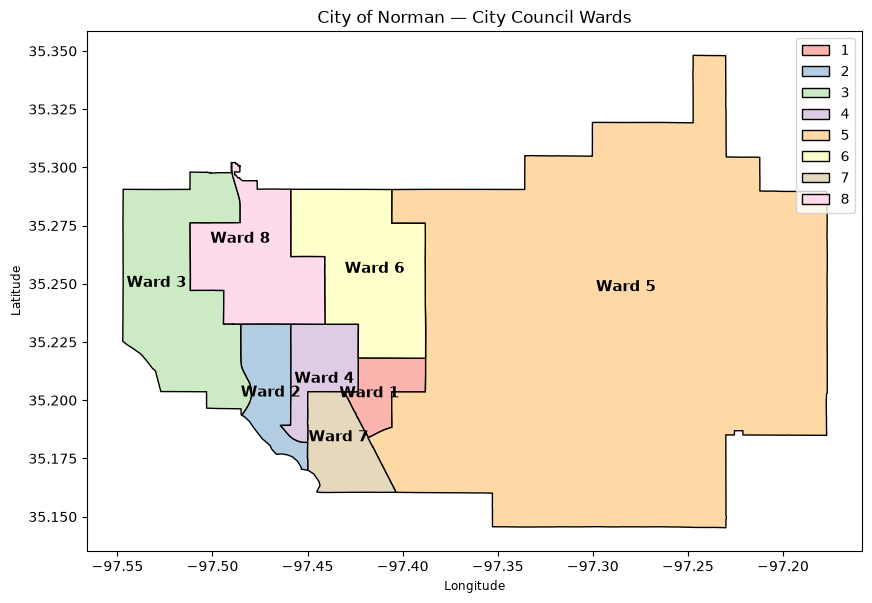

In [17]:
# Read the geojson file and create the dataframe
wards = gpd.read_file("Council_Wards_4934068591990916100.geojson")

# Overwrite the dataframe with only the relevant columns
wards = wards[['WARDNO', 'DIST_NAME', 'geometry']]

# I stole this code from my professor. This code will plot the wards
fig, ax = plt.subplots(figsize=(10, 8))
wards.plot(ax=ax, column='WARDNO', categorical=True, cmap='Pastel1', edgecolor='black', legend=True)

for i in range(len(wards)):
    shape = wards['geometry'].iloc[i]
    center = shape.representative_point()        # a point that is always inside the shape
    ax.text(center.x, center.y, 'Ward ' + str(wards['WARDNO'].iloc[i]), ha='center', fontsize=11, weight='bold')

ax.set_title('City of Norman — City Council Wards')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()


# Define a function for determining which ward a point is in

In [ ]:
from shapely.geometry import Point
# I stole this code from my professor again.
# This function will help me aggregate collisions by ward.
def find_ward(lat, lon):
    """Return the ward number that contains (lat, lon), or None."""
    p = Point(lon, lat)                 # careful: Point takes (x = longitude, y = latitude)
    for i in range(len(wards)):
        if wards['geometry'].iloc[i].contains(p):
            return wards['WARDNO'].iloc[i]
    return None

# Try it: a point on the OU campus, and a point on 12th Ave NE
print('OU campus  ->', find_ward(35.2059, -97.4457))
print('12th Ave NE ->', find_ward(35.2400, -97.4240))

OU campus  -> 4
12th Ave NE -> 6


# Adjust point locations

In [ ]:
# blah blah blah

# Add a column that denotes which ward a point is in

In [ ]:
# blah blah blah

# Aggregate points by ward and check the worst ones for each

In [ ]:
# blah blah blah

# Graph the most congested roads for each ward

In [ ]:
# blah blah blah